In [1]:
%%capture
!pip install sentence-transformers #>=2.2.0
!pip install plotly
!pip install wordcloud
!python -m spacy download en_core_web_lg
!pip install bertopic
!pip install nltk
!pip install gensim
!pip install scikit-learn

In [10]:
import os
import re
import pandas as pd
import numpy as np
from typing import Tuple
import copy as cp
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
from wordcloud import WordCloud
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
import torch
from collections import Counter
import warnings
warnings.filterwarnings('ignore')
import nltk
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
import spacy
import plotly.express as px
from sklearn.decomposition import NMF
from scipy.optimize import linear_sum_assignment
os.environ["PYDANTIC_V1_ALLOW"] = "true"  # allow v1 compatibility layer
print("✅ All libraries imported successfully!")

✅ All libraries imported successfully!


In [3]:
%%capture
!python -m spacy validate

In [4]:
#Import libraries for semantic analysis and other tasks
nlp = spacy.load("en_core_web_lg")

In [5]:
from warnings import warn
try:
    import datamapplot
    from matplotlib.figure import Figure
except ImportError:
    warn("Data map plotting is unavailable unless datamapplot is installed.")

    # Create a dummy figure type for typing
    class Figure(object):
        pass

In [6]:
import requests
def britishize(string):
    url ="https://raw.githubusercontent.com/hyperreality/American-British-English-Translator/master/data/american_spellings.json"
    american_to_british_dict = requests.get(url).json()

    for american_spelling, british_spelling in american_to_british_dict.items():
        string = string.replace(american_spelling, british_spelling)

    return string

In [11]:
file_path = '/content/drive/MyDrive/deep_learning_7_SV/Blatten_news/'
figure_path = '/content/drive/MyDrive/deep_learning_7_SV/Blatten_news/Figures/'

file_name = 'Blatten_DataExtraction_GivenLabels_20260313.csv'
df_orig = pd.read_csv(file_path + file_name)
len(df_orig)

2094

In [13]:
## Remove further duplicates using threshold semantic similarity. High thresholds imply almost same text.

model = SentenceTransformer("sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2")
texts = df_orig["content_en"].fillna("").tolist()

emb = model.encode(texts, batch_size=64, show_progress_bar=True, normalize_embeddings=True)

# cosine sim matrix (OK for a few thousand docs; for 10k+ use FAISS)
S = cosine_similarity(emb)

thr = 0.95  # tune: 0.88–0.95 typical
keep = []
dropped = set()

for i in range(len(texts)):
    if i in dropped:
        continue
    keep.append(i)

    # drop near-semantic duplicates of i
    dup_idx = np.where(S[i] >= thr)[0]
    for j in dup_idx:
        if j > i and j not in dropped:  # Only look forward to avoid order bias
            dropped.add(int(j))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batches:   0%|          | 0/33 [00:00<?, ?it/s]

In [14]:
def lemmatize_without_names_places(text):
    doc = nlp(str(text))
    lemmas = [
        token.lemma_
        for token in doc
        # keep only tokens that are NOT named entities of these types
        if token.ent_type_ not in {"PERSON", "ORG", "GPE", "LOC"}
    ]
    return " ".join(lemmas)

In [15]:
# Remove duplicated
df_orig= df_orig.drop_duplicates(subset="id", keep="first")   # or keep="last"

In [16]:
unique_df = df_orig.iloc[keep].copy()
# After deduplication, verify:
print(f"Kept: {len(keep)}, Dropped: {len(dropped)}")
print(f"Removal rate: {len(dropped)/len(texts)*100:.1f}%")

# Spot-check some dropped pairs
sample_dropped = list(dropped)[:5]
for idx in sample_dropped:
    # Find what it was similar to
    kept_similar = [i for i in keep if S[idx, i] >= thr]
    if kept_similar:
        print(f"\n--- Dropped article {idx} (similar to {kept_similar[0]}) ---")
        print(f"Similarity: {S[idx, kept_similar[0]]:.3f}")
        print(f"Kept: {texts[kept_similar[0]][:400]}...")
        print(f"Drop: {texts[idx][:400]}...")

unique_df["event_llm"] = unique_df["event_llm"].str.replace(
    "permafrost melting",
    "permafrost thawing",
    regex=False
)
npr = unique_df.copy()
npr.reset_index(inplace = True)

Kept: 2052, Dropped: 42
Removal rate: 2.0%

--- Dropped article 1155 (similar to 957) ---
Similarity: 0.960
Kept: The debris cone of the mountain collapse in Blatten VS is, according to the chief of the Valais office for natural hazards, locally over meters high. Swiss insurer Risse or larger collapses of the debris pile have not been detected so far, as Raphaël Mayoraz told the media. But that could change as soon as the ice starts to melt, Mayoraz said in an interview with the newspapers «Walliser Bote», «L...
Drop: The debris cone of the mountain collapse in Blatten VS is, according to the head of the Valais office for natural hazards, locally over metres high. Cracks or larger collapses of the debris pile have not been detected so far, as Raphaël Mayoraz told the media. But that could change as soon as the ice begins to melt, Mayoraz said in an interview with the newspapers «Walliser Bote», «Le Nouvelliste»...

--- Dropped article 1800 (similar to 1147) ---
Similarity: 0.979
Kept: 

## Analyse sources

In [17]:
unique_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2052 entries, 0 to 2093
Data columns (total 42 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Unnamed: 0               2052 non-null   int64  
 1   id                       2052 non-null   int64  
 2   pubtime                  2052 non-null   object 
 3   medium_code              2052 non-null   object 
 4   medium_name              2052 non-null   object 
 5   rubric                   1360 non-null   object 
 6   regional                 99 non-null     object 
 7   doctype                  2052 non-null   object 
 8   doctype_description      2052 non-null   object 
 9   language                 2052 non-null   object 
 10  char_count               2052 non-null   int64  
 11  dateline                 353 non-null    object 
 12  head                     2052 non-null   object 
 13  subhead                  78 non-null     object 
 14  article_link             1099

In [18]:
media = (unique_df.groupby(["medium_name", "medium_code"], as_index=False)
           .agg(n_articles=("id", "count"),
                total_chars=("char_count", "sum"),
                mean_chars=("char_count", "mean"))
           .sort_values("n_articles", ascending=False)
           .reset_index(drop=True))

media["share_articles_pct"] = (100 * media["n_articles"] / media["n_articles"].sum()).round(1)
media["mean_chars"] = media["mean_chars"].round(0).astype(int)
print(media)

              medium_name medium_code  n_articles  total_chars  mean_chars  \
0                blick.ch        BLIO         241       999876        4149   
1                  srf.ch         SRF         170       583432        3432   
2            swissinfo.ch        SWII          84       477870        5689   
3      aargauerzeitung.ch         AZO          78       371007        4756   
4              letemps.ch        TPSO          78       371216        4759   
..                    ...         ...         ...          ...         ...   
83             Beobachter         BEO           1         8088        8088   
84    Schweizer LandLiebe         LAL           1         1751        1751   
85                   Tele        TELE           1         1417        1417   
86      Schweizer Familie          SF           1          924         924   
87  limmattalerzeitung.ch        LTZO           1         1235        1235   

    share_articles_pct  
0                 11.7  
1            

In [19]:
#media.to_excel('media_count.xlsx')
media=pd.read_excel('/content/media_count.xlsx',sheet_name='Medium_Grouped')

In [20]:
media

,Medium Name,Count
0,SRG SSR,391
1,Blick,316
2,20 minutes,170
3,Neue Zürcher Zeitung,140
4,Le Temps,126
5,Aargauer Zeitung,100
6,24 heures,75
7,Tribune de Genève,72
8,Le Matin,70
9,Handelszeitung,57


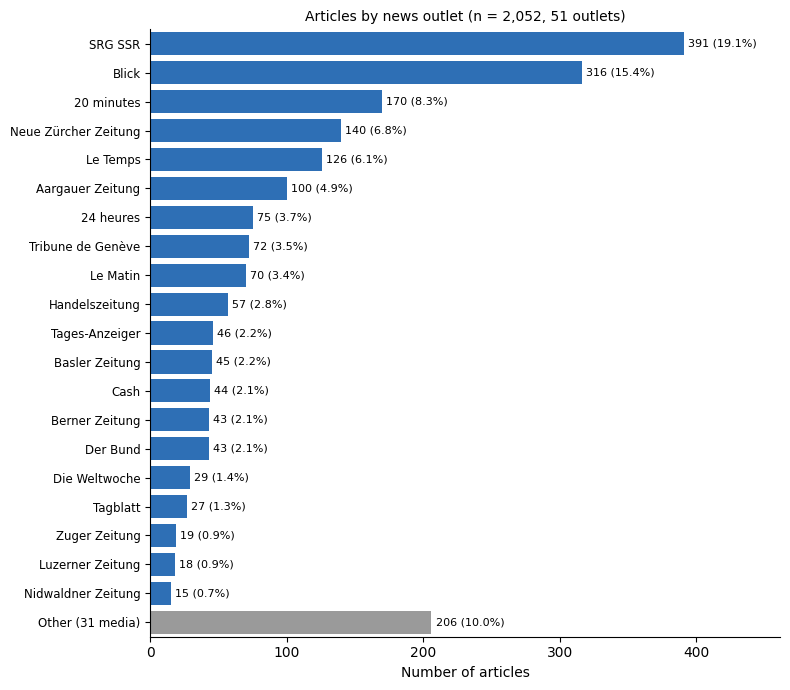

In [23]:
TOP = 20
df_m = media.dropna(subset=["Medium Name"]).sort_values("Count", ascending=False).reset_index(drop=True)
total = df_m["Count"].sum()

top = df_m.head(TOP)
rest = df_m.iloc[TOP:]
plot = pd.concat([top, pd.DataFrame({"Medium Name": [f"Other ({len(rest)} media)"],
                                     "Count": [rest["Count"].sum()]})], ignore_index=True)
plot["pct"] = 100 * plot["Count"] / total
plot = plot[::-1].reset_index(drop=True)          # largest at the top

fig, ax = plt.subplots(figsize=(8, 7))
colors = ["#9a9a9a"] + ["#2e6fb5"] * TOP            # "Other" (now first row) in grey
ax.barh(plot["Medium Name"], plot["Count"], color=colors)
for y, (c, p) in enumerate(zip(plot["Count"], plot["pct"])):
    ax.text(c + 3, y, f"{c} ({p:.1f}%)", va="center", fontsize=8)

ax.set_ylim(-0.5, len(plot) - 0.5)                  # no blank space above/below the bars
ax.set_xlim(0, plot["Count"].max() * 1.18)
ax.set_xlabel("Number of articles")
ax.set_title(f"Articles by news outlet (n = {total:,}, {len(df_m)} outlets)", fontsize=10)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
ax.tick_params(axis="y", labelsize=8.5)
plt.tight_layout()
plt.savefig("articles_by_outlet.png", dpi=300)
plt.savefig("articles_by_outlet.svg", dpi=300)
plt.show()

## Topic Modelling: Topic Number

In [18]:
npr['clean_content_en'] = npr['content_en'].astype(str)
npr["abstract_lemmatized"] = npr["clean_content_en"].apply(lemmatize_without_names_places)

In [19]:
nlp.Defaults.stop_words |= {'Blatten', 'blatten','monday', 'tuesday', 'wednesday', 'friday', 'thursday','saturday', 'sunday','village','swiss', 'press','conference', 'press conference', 'switzerland', 'Switzerland', 'lötschental', 'blatten lötschental', 'valais', 'blatten vs', 'vs','cubic', 'metre',
                            'cubic metre', 'million metre','million cubic','die', 'ist', 'und', 'der', 'wir', 'es', 'das', 'ein', 'den', 'zu', 'haben', 'nicht', 'für', 'sind', 'eine', 'ich', 'dass', 'mit', 'werden', 'house',
                            'de', 'la', 'le', 'les', 'et', 'des', 'nous', 'est', 'pas', 'du', 'en', 'il', 'un', 'pour',
                            'plus', 'une', 'dans', 'que', 'se', 'inhabitant','ticker', 'news ticker', 'qr', 'qr code',
                            'night', 'day', 'journal', 'news', 'win', 'play live', 'live win', 'quiz', 'live quiz'}

stop_words_2 = nlp.Defaults.stop_words

In [20]:
BIGRAM_SYNONYMS = {
    #"million cubic": "cubic meter",
    "mountain crash": "mountain fall",
    "municipality blatten": "municipality",
    "municipality Blatten": "municipality"
    #"meter meter": "cubic meter"

}

def normalize_synonyms(text: str) -> str:
    txt = text.lower()
    for variant, canon in BIGRAM_SYNONYMS.items():
        txt = re.sub(rf"\b{re.escape(variant)}\b", canon, txt)

    return txt

In [21]:
# Matches a sentence that contains download or quiz related news (case-insensitive)
SENT_WITH_BAD_WORD = re.compile(
    r'(?is)(?:^|(?<=[.!?]))\s*[^.!?]*\b(?:download|quiz)\b[^.!?]*[.!?]?\s*'
)

def remove_sentences_with_download_quiz(text: str) -> str:
    if not isinstance(text, str) or not text.strip():
        return text
    cleaned = SENT_WITH_BAD_WORD.sub(" ", text)
    # tidy spacing
    cleaned = re.sub(r'\s+', ' ', cleaned).strip()
    return cleaned

In [22]:
# Apply synonym normalization
npr['abstract_norm'] = npr['abstract_lemmatized'].apply(normalize_synonyms)
npr['abstract_norm'] = npr['abstract_norm'].apply(remove_sentences_with_download_quiz)

In [23]:
#bigrams
tfidf = TfidfVectorizer(
    max_df=0.95, min_df=2, ngram_range=(1,2),
    stop_words=list(stop_words_2),
)
dtm = tfidf.fit_transform(npr["abstract_norm"])

In [32]:
# Fit NMF
nmf_model = NMF(n_components=7, random_state=43)
nmf_model.fit(dtm)

# How many top words per topic
n_top_words = 20   # change to 10 if you like

feature_names = tfidf.get_feature_names_out()
topics_list = []

for index, topic in enumerate(nmf_model.components_):
    # indices of top n words, sorted from highest to lowest weight
    top_indices = topic.argsort()[-n_top_words:][::-1]
    top_words = [feature_names[i] for i in top_indices]

    print(f"TOP {n_top_words} WORDS FOR TOPIC #{index}")
    print(top_words)
    print()

    topics_list.append(top_words)

# ---- Save to CSV (one row per topic, one column per rank) ----
topics_df = pd.DataFrame(
    topics_list,
    index=[f"topic_{i}" for i in range(len(topics_list))]
)

TOP 20 WORDS FOR TOPIC #0
['people', 'mountain', 'live', 'valley', 'home', 'year', 'lose', 'life', 'time', 'know', 'want', 'disaster', 'family', 'leave', 'rebuild', 'president', 'long', 'new', 'like', 'place']

TOP 20 WORDS FOR TOPIC #1
['aid', 'franc', 'million', 'million franc', 'fund', 'federal', 'support', 'government', 'immediate', 'municipality', 'emergency', 'reconstruction', 'emergency aid', 'measure', 'decide', 'immediate aid', 'disaster', 'contribution', 'law', 'urgent']

TOP 20 WORDS FOR TOPIC #2
['climate', 'change', 'climate change', 'permafrost', 'warming', 'increase', 'risk', 'heat', 'country', 'temperature', 'year', 'weather', 'mountain', 'event', 'emission', 'global', 'degree', 'link', 'warm', 'climate warming']

TOP 20 WORDS FOR TOPIC #3
['insurance', 'damage', 'insurer', 'building', 'loss', 'insure', 'pool', 'natural', 'private', 'premium', 'risk', 'private insurer', 'franc', 'flood', 'building insurance', 'year', 'percent', 'company', 'cause', 'million franc']

TOP 

In [25]:
# Evaluation of the number of NMF topics
# Assumes the objects from your notebook already exist:
#   tfidf  (fitted TfidfVectorizer, ngram_range=(1,2))
#   dtm    (TF-IDF document-term matrix)
#   npr    (DataFrame with column "abstract_norm")
# Each "# %%" block can be pasted into its own notebook cell.

feature_names = tfidf.get_feature_names_out()
N_TOP = 10                      # top terms per topic used for evaluation
K_RANGE = range(5, 31)          # candidate numbers of topics
NMF_KW = dict(random_state=43)  # keep identical to your main model settings

# Binary document-term matrix for co-occurrence counts
X_bin = (dtm > 0).astype(np.int32).tocsc()
N_DOCS = X_bin.shape[0]


In [26]:
def top_indices(model, n=N_TOP):
    """Indices of the n highest-weighted terms for each topic."""
    return [comp.argsort()[-n:][::-1] for comp in model.components_]


# %% 1. Coherence (document-level NPMI) and topic diversity
def npmi_topic(idx, eps=1e-12):
    """Mean NPMI over all pairs of top terms, using document co-occurrence."""
    sub = X_bin[:, idx]
    co = (sub.T @ sub).toarray()          # pairwise co-document counts
    df = np.diag(co).astype(float)
    scores = []
    for a in range(len(idx)):
        for b in range(a + 1, len(idx)):
            p_ij = co[a, b] / N_DOCS
            if p_ij == 0:
                scores.append(-1.0)       # never co-occur -> minimum NPMI
                continue
            if p_ij >= 1 - eps:
                scores.append(1.0)
                continue
            p_i, p_j = df[a] / N_DOCS, df[b] / N_DOCS
            pmi = np.log(p_ij / (p_i * p_j))
            scores.append(pmi / -np.log(p_ij))
    return float(np.mean(scores))


def topic_diversity(model, n=25):
    """Share of unique terms among the top-n terms of all topics (1 = no overlap)."""
    tops = top_indices(model, n)
    all_terms = np.concatenate(tops)
    return len(set(all_terms)) / len(all_terms)


# %% 2. Stability across document subsamples (after Greene et al. 2014)
def jaccard(a, b):
    a, b = set(a), set(b)
    return len(a & b) / len(a | b)


def stability(k, ref_tops, n_runs=10, frac=0.8, seed=0):
    """Mean matched Jaccard similarity between the reference topics and
    topics from models fitted on random 80% subsamples of documents."""
    rng = np.random.default_rng(seed)
    run_scores = []
    for r in range(n_runs):
        rows = rng.choice(N_DOCS, size=int(frac * N_DOCS), replace=False)
        m = NMF(n_components=k, random_state=r).fit(dtm[rows])
        tops = top_indices(m)
        sim = np.array([[jaccard(a, b) for b in tops] for a in ref_tops])
        r_idx, c_idx = linear_sum_assignment(-sim)   # best one-to-one matching
        run_scores.append(sim[r_idx, c_idx].mean())
    return float(np.mean(run_scores)), float(np.std(run_scores))


# %% 3a. Fast sweep: coherence and diversity for every k (one fit per k, parallel)
import time
from joblib import Parallel, delayed


def eval_k(k):
    model = NMF(n_components=k, **NMF_KW).fit(dtm)
    tops = top_indices(model)
    npmi = [npmi_topic(idx) for idx in tops]
    return {"k": k, "npmi_mean": np.mean(npmi), "npmi_sd": np.std(npmi),
            "diversity": topic_diversity(model),
            "reconstruction_err": model.reconstruction_err_, "tops": tops}

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   9 out of  26 | elapsed:   21.0s remaining:   39.8s
[Parallel(n_jobs=-1)]: Done  15 out of  26 | elapsed:   38.4s remaining:   28.2s
[Parallel(n_jobs=-1)]: Done  21 out of  26 | elapsed:   52.8s remaining:   12.6s
[Parallel(n_jobs=-1)]: Done  26 out of  26 | elapsed:  1.2min finished


Coherence sweep done in 71 s


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   9 out of  26 | elapsed:  2.7min remaining:  5.2min
[Parallel(n_jobs=-1)]: Done  15 out of  26 | elapsed:  6.0min remaining:  4.4min
[Parallel(n_jobs=-1)]: Done  21 out of  26 | elapsed: 10.2min remaining:  2.4min
[Parallel(n_jobs=-1)]: Done  26 out of  26 | elapsed: 14.7min finished


Stability done in 883 s
 k  npmi_mean  npmi_sd  diversity  reconstruction_err  stability_mean  stability_sd
 5      0.339    0.213      0.912              43.916           0.825         0.043
 6      0.326    0.199      0.873              43.803           0.692         0.123
 7      0.331    0.184      0.863              43.707           0.824         0.076
 8      0.331    0.174      0.840              43.621           0.855         0.030
 9      0.332    0.162      0.840              43.554           0.754         0.064
10      0.330    0.153      0.820              43.483           0.778         0.119
11      0.310    0.155      0.804              43.417           0.762         0.053
12      0.320    0.151      0.817              43.348           0.745         0.073
13      0.356    0.187      0.831              43.294           0.714         0.037
14      0.349    0.169      0.814              43.239           0.693         0.050
15      0.351    0.160      0.800              43.18

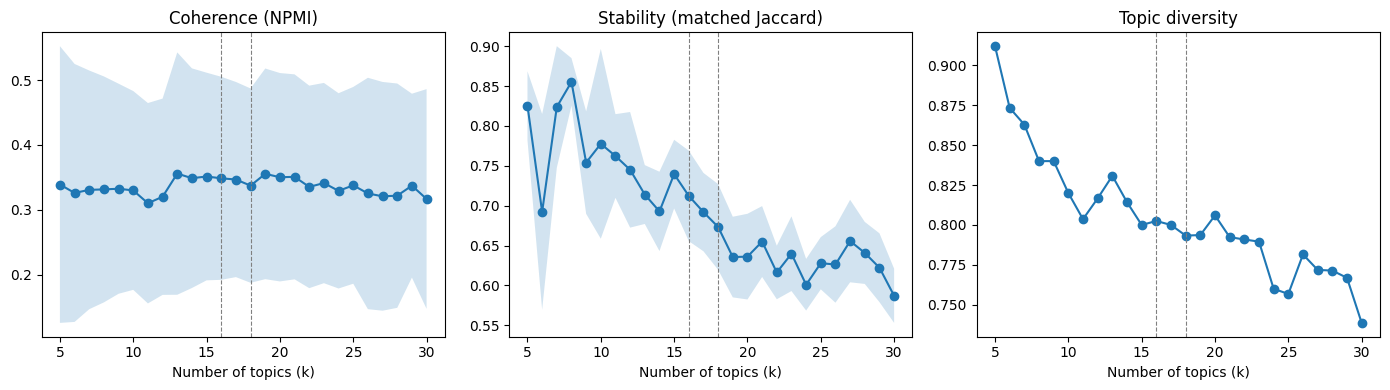

   topic     npmi                                                                                                                             top_terms  n_docs_dominant
 topic_0 0.182287                                                                    people, mountain, live, valley, home, life, lose, know, time, year              223
topic_17 0.203334                                                    reconstruction, new, rebuild, plan, hamlet, return, present, road, timetable, year              166
 topic_5 0.208572                                 rock, mountain, collapse, permafrost, fall, mountain collapse, million, rockfall, million rock, large              136
topic_12 0.214603                                            glacier, ice, snow, melt, break, collapse, retreat, million tonne, tonne, glacier collapse              105
 topic_7 0.275952                                                     hazard, map, zone, hazard map, natural hazard, natural, risk, red, building, area    

In [24]:
t0 = time.time()
results = Parallel(n_jobs=-1, verbose=5)(delayed(eval_k)(k) for k in K_RANGE)
print(f"Coherence sweep done in {time.time() - t0:.0f} s")


# %% 3b. Stability on a coarser grid, dense around 16-18 (the slow part)
K_STAB = [5, 6, 7, 8, 9, 10, 11, 12, 13, 14,
          15, 16, 17, 18, 19, 20, 21, 22,
          23, 24, 25, 26, 27, 28, 29,30]
N_RUNS = 10   # raise to 10 for the final version if time allows

stab_res = [r for r in results if r["k"] in K_STAB]
t0 = time.time()
stab = Parallel(n_jobs=-1, verbose=5)(
    delayed(stability)(r["k"], r["tops"], n_runs=N_RUNS) for r in stab_res)
print(f"Stability done in {time.time() - t0:.0f} s")
stab_map = {r["k"]: s for r, s in zip(stab_res, stab)}

eval_df = pd.DataFrame([{c: v for c, v in r.items() if c != "tops"}
                        for r in results])
eval_df["stability_mean"] = eval_df["k"].map(lambda k: stab_map.get(k, (np.nan, np.nan))[0])
eval_df["stability_sd"] = eval_df["k"].map(lambda k: stab_map.get(k, (np.nan, np.nan))[1])
eval_df.to_csv("topic_number_evaluation.csv", index=False)
print(eval_df.round(3).to_string(index=False))


# %% 4. Plot for the supplementary material
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True)
panels = [("npmi_mean", "npmi_sd", "Coherence (NPMI)"),
          ("stability_mean", "stability_sd", "Stability (matched Jaccard)"),
          ("diversity", None, "Topic diversity")]
for ax, (col, sd, label) in zip(axes, panels):
    d = eval_df.dropna(subset=[col])      # stability exists only on K_STAB
    ax.plot(d["k"], d[col], marker="o")
    if sd:
        ax.fill_between(d["k"], d[col] - d[sd], d[col] + d[sd], alpha=0.2)
    for k_mark in (16, 18):
        ax.axvline(k_mark, ls="--", c="grey", lw=0.8)
    ax.set_title(label)
    ax.set_xlabel("Number of topics (k)")
plt.tight_layout()
plt.savefig("topic_number_evaluation.png", dpi=300)
plt.show()


# %% 5. Per-topic coherence of the 18-topic model (to justify dropping/merging two)
model_18 = NMF(n_components=18, **NMF_KW).fit(dtm)
tops_18 = top_indices(model_18)
per_topic = pd.DataFrame({
    "topic": [f"topic_{i}" for i in range(18)],
    "npmi": [npmi_topic(idx) for idx in tops_18],
    "top_terms": [", ".join(feature_names[idx]) for idx in tops_18],
    "n_docs_dominant": np.bincount(model_18.transform(dtm).argmax(axis=1),
                                   minlength=18),
}).sort_values("npmi")
print(per_topic.to_string(index=False))

# Term overlap between topics: high values flag near-duplicate topics to merge
overlap = pd.DataFrame(
    [[jaccard(a, b) for b in tops_18] for a in tops_18],
    index=range(18), columns=range(18))
np.fill_diagonal(overlap.values, 0)
print("\nMost overlapping topic pairs:")
print(overlap.stack().sort_values(ascending=False).drop_duplicates().head(5))

In [9]:
if "eval_df" in globals() and isinstance(eval_df, pd.DataFrame):
    print("eval_df is already loaded.")
else:
    file_path = "/content/topic_number_evaluation_3.csv"

    if os.path.exists(file_path):
        eval_df = pd.read_csv(file_path)
        print("eval_df loaded from /content/")
    else:
        print("Please upload topic_number_evaluation.csv to /content/")

eval_df.head() if "eval_df" in globals() else None

eval_df is already loaded.


,k,npmi_mean,npmi_sd,diversity,reconstruction_err,stability_mean,stability_sd
0,5,0.338850,0.213357,0.912000,43.915719,0.825455,0.043179
1,6,0.325881,0.198906,0.873333,43.802517,0.692246,0.122784
2,7,0.330643,0.184033,0.862857,43.706574,0.823871,0.076287
3,8,0.331332,0.174199,0.840000,43.621286,0.855303,0.029864
4,9,0.332364,0.161985,0.840000,43.553955,0.754101,0.064264


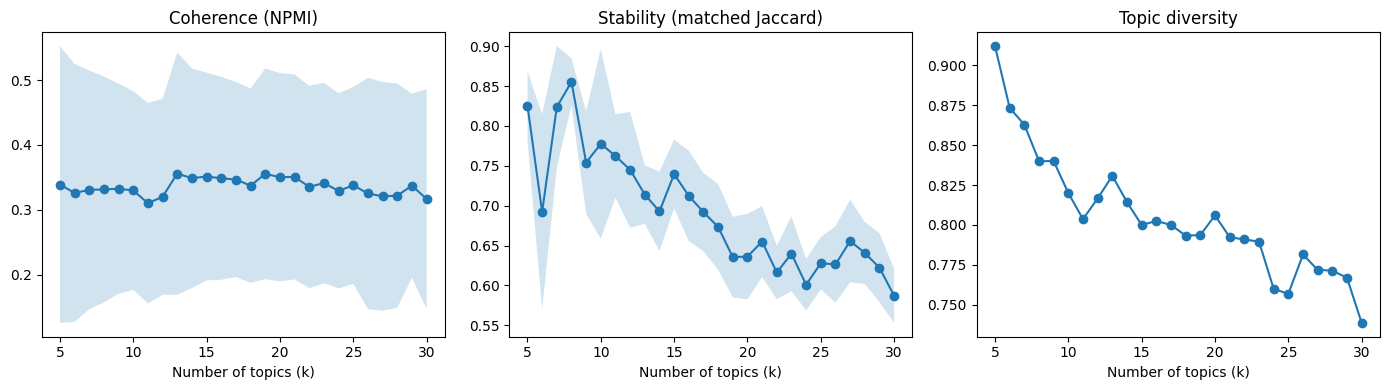

In [10]:
# %% 4. Plot for the supplementary material (if you don't want to re-run the evaluation and only load the csv file)
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True)
panels = [("npmi_mean", "npmi_sd", "Coherence (NPMI)"),
          ("stability_mean", "stability_sd", "Stability (matched Jaccard)"),
          ("diversity", None, "Topic diversity")]
for ax, (col, sd, label) in zip(axes, panels):
    ax.plot(eval_df["k"], eval_df[col], marker="o")
    if sd:
        ax.fill_between(eval_df["k"], eval_df[col] - eval_df[sd],
                        eval_df[col] + eval_df[sd], alpha=0.2)
    #for k_mark in (13, 21):
    #    ax.axvline(k_mark, ls="--", c="grey", lw=0.8)
    ax.set_title(label)
    ax.set_xlabel("Number of topics (k)")
plt.tight_layout()
plt.savefig("topic_number_evaluation.svg", dpi=300)
plt.savefig("topic_number_evaluation.png", dpi=300)
plt.show()

In [27]:
from itertools import combinations
mpj = {}
for k in range(5, 31):
    tops = top_indices(NMF(n_components=k, random_state=43).fit(dtm))
    mpj[k] = np.mean([jaccard(a, b) for a, b in combinations(tops, 2)])
eval_df["mpj"] = eval_df["k"].map(mpj)
print(eval_df[["k", "diversity", "mpj"]].round(3))


# NPMI band = standard error of the mean across topics (SD / sqrt(k));
# stability band = SD across subsample runs.
K_SELECTED = 18

d = eval_df.copy()
d["npmi_se"] = d["npmi_sd"] / np.sqrt(d["k"])

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True)
panels = [("npmi_mean", "npmi_se", "Coherence (NPMI, mean ± SE)"),
          ("stability_mean", "stability_sd", "Stability (matched Jaccard, mean ± SD)"),
          ("diversity", None, "Topic diversity")]
for letter, ax, (col, band, label) in zip("abc", axes, panels):
    dd = d.dropna(subset=[col])
    ax.plot(dd["k"], dd[col], marker="o", ms=4)
    if band:
        ax.fill_between(dd["k"], dd[col] - dd[band], dd[col] + dd[band], alpha=0.2)
    ax.axvline(K_SELECTED, ls="--", c="grey", lw=0.8)
    ax.set_title(f"({letter}) {label}", fontsize=10, loc="left")
    ax.set_xlabel("Number of topics (k)")
axes[0].text(K_SELECTED + 0.3, axes[0].get_ylim()[1], f"k = {K_SELECTED}",
             va="top", fontsize=8, color="grey")
plt.tight_layout()
plt.savefig("topic_number_evaluation.svg", dpi=300)
plt.show()

KeyboardInterrupt: 

In [28]:
# Test for sensitivity
import time

tops_by_k = {}
t_start = time.time()
for k in range(5, 31):
    t0 = time.time()
    tops_by_k[k] = top_indices(NMF(n_components=k, random_state=43).fit(dtm))
    print(f"k={k:2d} fitted in {time.time() - t0:.0f} s  "
          f"({len(tops_by_k)}/20 done, {time.time() - t_start:.0f} s total)", flush=True)

def recovery(ref, other, thr=0.5):
    best = np.array([[jaccard(a, b) for b in other] for a in ref]).max(axis=1)
    return (best >= thr).mean(), best.mean()

rows = []
for k in range(3, 33):
    rec = [recovery(tops_by_k[k], tops_by_k[j]) for j in (k - 2, k - 1, k + 1, k + 2)]
    rows.append({"k": k,
                 "share_recovered": np.mean([r[0] for r in rec]),
                 "mean_match": np.mean([r[1] for r in rec])})
robust = pd.DataFrame(rows).round(3)
print(robust.to_string(index=False))

k= 5 fitted in 4 s  (1/20 done, 4 s total)
k= 6 fitted in 3 s  (2/20 done, 7 s total)
k= 7 fitted in 2 s  (3/20 done, 9 s total)
k= 8 fitted in 2 s  (4/20 done, 11 s total)
k= 9 fitted in 2 s  (5/20 done, 13 s total)
k=10 fitted in 2 s  (6/20 done, 15 s total)
k=11 fitted in 5 s  (7/20 done, 21 s total)
k=12 fitted in 6 s  (8/20 done, 26 s total)
k=13 fitted in 7 s  (9/20 done, 33 s total)
k=14 fitted in 7 s  (10/20 done, 40 s total)
k=15 fitted in 8 s  (11/20 done, 48 s total)
k=16 fitted in 8 s  (12/20 done, 56 s total)
k=17 fitted in 11 s  (13/20 done, 67 s total)
k=18 fitted in 12 s  (14/20 done, 79 s total)
k=19 fitted in 16 s  (15/20 done, 95 s total)
k=20 fitted in 12 s  (16/20 done, 107 s total)
k=21 fitted in 15 s  (17/20 done, 122 s total)
k=22 fitted in 18 s  (18/20 done, 140 s total)
k=23 fitted in 18 s  (19/20 done, 158 s total)
k=24 fitted in 32 s  (20/20 done, 190 s total)
k=25 fitted in 17 s  (21/20 done, 207 s total)
k=26 fitted in 15 s  (22/20 done, 222 s total)
k=27 

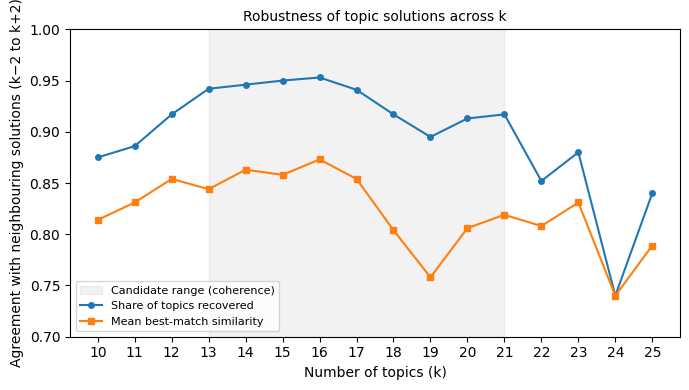

In [30]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.axvspan(13, 21, color="grey", alpha=0.1, label="Candidate range (coherence)")
ax.plot(robust["k"], robust["share_recovered"], marker="o", ms=4,
        label="Share of topics recovered")
ax.plot(robust["k"], robust["mean_match"], marker="s", ms=4,
        label="Mean best-match similarity")
#ax.axvline(K_SELECTED, ls="--", c="grey", lw=0.8)
#ax.text(K_SELECTED + 0.2, 0.71, f"k = {K_SELECTED}", fontsize=8, color="grey")
ax.set_xlabel("Number of topics (k)")
ax.set_ylabel("Agreement with neighbouring solutions (k−2 to k+2)")
ax.set_xticks(robust["k"])
ax.set_ylim(0.7, 1.0)
ax.legend(fontsize=8, loc="lower left")
ax.set_title("Robustness of topic solutions across k", fontsize=10)
plt.tight_layout()
plt.savefig("topic_robustness_neighbours.svg", dpi=300)
plt.show()

In [34]:
#Sensitivity shows 16 will be preferred. Let's check what is the difference with 18
NMF_KW = dict(random_state=43)  # keep identical to main model settings
model_18 = NMF(n_components=18, **NMF_KW).fit(dtm)

# Redefine N_TOP and top_indices function to ensure it's available
N_TOP = 10  # This should match the definition in the topic evaluation cell
def top_indices(model, n=N_TOP):
    """Indices of the n highest-weighted terms for each topic."""
    return [comp.argsort()[-n:][::-1] for comp in model.components_]

def jaccard(a, b):
    a, b = set(a), set(b)
    return len(a & b) / len(a | b)

ref = [t for i, t in enumerate(top_indices(model_18))] #if i not in (4, 14)
for k in [7,8,9,10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25]:
    tops = top_indices(NMF(n_components=k, random_state=43).fit(dtm))
    best = np.array([[jaccard(a, b) for b in tops] for a in ref]).max(axis=1)
    sim = np.array([[jaccard(a, b) for b in tops] for a in ref])
    for i in np.where(best < 0.5)[0]:
        j = sim[i].argmax()
        print(f"   not recovered: {', '.join(feature_names[ref[i][:5]])}"
              f"  ->  closest: {', '.join(feature_names[tops[j][:5]])}")
    print(f"k={k}: mean best match = {best.mean():.2f}, "
          f"topics recovered (Jaccard \u2265 0.5) = {(best >= 0.5).sum()}/18")

   not recovered: rock, mountain, collapse, permafrost, fall  ->  closest: glacier, rock, collapse, mountain, fall
   not recovered: hazard, map, zone, hazard map, natural hazard  ->  closest: insurance, damage, insurer, building, natural
   not recovered: hotel, tourism, guest, season, tourist  ->  closest: people, hotel, mountain, valley, new
   not recovered: municipal, council, municipal council, municipality, franc  ->  closest: franc, aid, donation, million franc, million
   not recovered: situation, evacuate, staff, command, command staff  ->  closest: people, hotel, mountain, valley, new
   not recovered: search, police, miss, operation, search operation  ->  closest: lake, debris, army, water, cone
   not recovered: glacier, ice, snow, melt, break  ->  closest: glacier, rock, collapse, mountain, fall
   not recovered: donation, organisation, aid, franc, money  ->  closest: franc, aid, donation, million franc, million
   not recovered: collection campaign, campaign, donation wa